# Setup

In [130]:
import numpy as np

import matplotlib.pyplot as plt

In [131]:
plt.style.use("default")
%config InlineBackend.figure_format = 'retina'

# Parameters

In [132]:
MAX_NDVI = 0.4
MIN_NDVI = 0.0

MAX_CHLA_MG_M2 = 60
MIN_CHLA_MG_M2 = 0

N_POINTS = 10000
N_SAMPLES = 30

seed = 42
np.random.seed(seed)

# Simulate

In [133]:
slope = (MAX_CHLA_MG_M2 - MIN_CHLA_MG_M2) / (MAX_NDVI - MIN_NDVI)
intercept = MIN_CHLA_MG_M2 - slope * MIN_NDVI

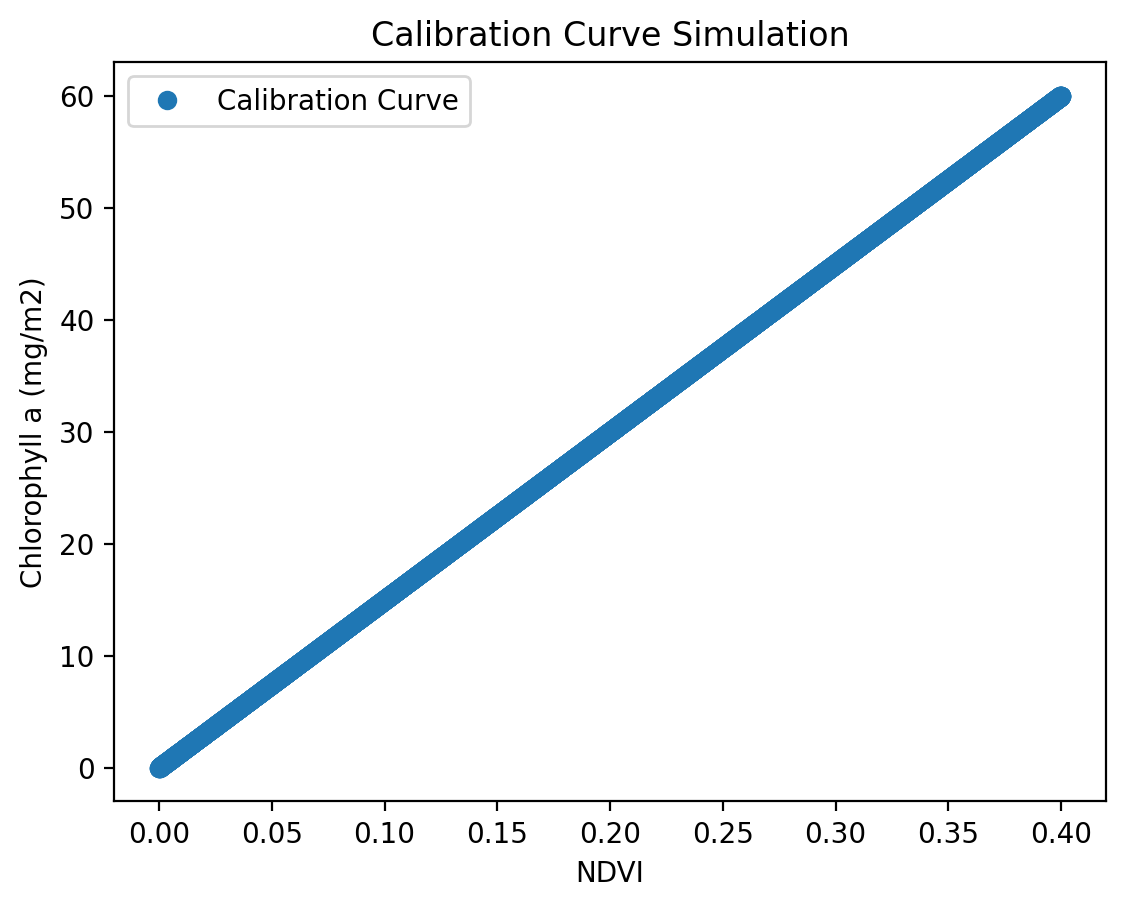

In [134]:
# Create uniform distribution of chlorophyll a values
chla_values = np.linspace(MIN_CHLA_MG_M2, MAX_CHLA_MG_M2, N_POINTS)

# Create corresponding NDVI values using the calibration curve
ndvi_values = (chla_values - intercept) / slope

# Plot the calibration curve

plt.plot(ndvi_values, chla_values, 'o', label="Calibration Curve")
plt.xlabel("NDVI")
plt.ylabel("Chlorophyll a (mg/m2)")
plt.title("Calibration Curve Simulation")
plt.legend()
plt.show()

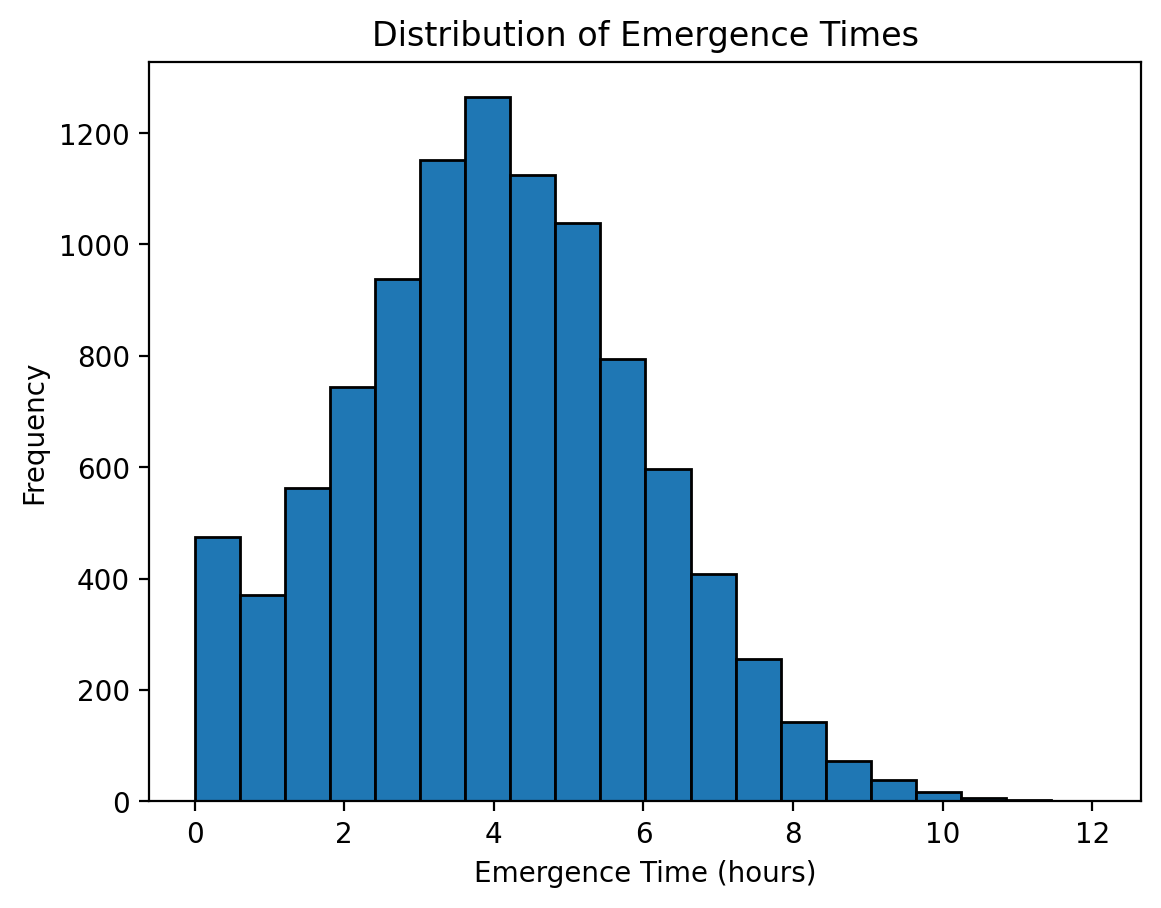

In [135]:
# Distribution of emergence times, normal
mean_emergence_time_hours = 4
std_emergence_time_hours = 2

emergence_times_hours = np.random.default_rng(seed).normal(mean_emergence_time_hours, std_emergence_time_hours, N_POINTS)
emergence_times_hours = np.clip(emergence_times_hours, 0, None)  # Ensure no negative emergence times

plt.hist(emergence_times_hours, bins=20, edgecolor='black')
plt.xlabel("Emergence Time (hours)")
plt.ylabel("Frequency")
plt.title("Distribution of Emergence Times")
plt.show()

In [136]:
# Create different responses function, between 0 and 1, to give full emersion (migration) of biofilm with time


def smooth_transition(x, shape=2.0):
    """
    Smooth monotonic transition from 0 to 1.

    Parameters
    ----------
    x : float or array-like
        Normalized time between 0 and 1.

    shape : float
        Controls transition abruptness.

        shape = 1:
            Linear transition.

        shape > 1:
            S-shaped transition.

        Larger values:
            More abrupt change around the midpoint.

    Returns
    -------
    float or numpy.ndarray
        Smooth transition between 0 and 1.
    """
    if shape <= 0:
        raise ValueError("shape must be positive.")

    scalar_input = np.isscalar(x)
    x = np.asarray(x, dtype=float)
    x = np.clip(x, 0.0, 1.0)

    numerator = x**shape
    denominator = numerator + (1.0 - x)**shape

    result = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator > 0,
    )

    if scalar_input:
        return float(result)

    return result


def diel_biofilm_expression(
    t,
    t_start=0.0,
    t_fast=1.0,
    t_peak=5.0,
    t_plateau_end=8.0,
    t_end=11.0,
    start_level=0.0,
    fast_level=0.80,
    peak_level=1.0,
    end_level=0.0,
    fast_shape=2.0,
    slow_shape=1.2,
    decline_shape=1.5,
    outside_value=0.0,
):
    """
    Two-stage diel model of MPB surface expression.

    The model contains four phases:

    1. Rapid upward migration:
       t_start to t_fast

    2. Slow surface consolidation:
       t_fast to t_peak

    3. Plateau:
       t_peak to t_plateau_end

    4. Downward migration:
       t_plateau_end to t_end

    Parameters
    ----------
    t : float or array-like
        Time since emersion, normally in hours.

    t_start : float
        Beginning of the modeled emersion period.

    t_fast : float
        Time at which rapid initial migration ends.

    t_peak : float
        Time at which maximum surface expression is reached.

    t_plateau_end : float
        Time at which the plateau ends and decline begins.

    t_end : float
        End of the modeled emersion period.

    start_level : float
        Surface-expression index at t_start.

    fast_level : float
        Surface-expression index reached at t_fast.

        For the rapid-migration hypothesis in the notes,
        this could be approximately 0.8.

    peak_level : float
        Maximum surface-expression index.

    end_level : float
        Surface-expression index immediately before inundation.

    fast_shape : float
        Shape of the rapid migration phase.

    slow_shape : float
        Shape of the slower consolidation phase.

    decline_shape : float
        Shape of the downward migration phase.

    outside_value : float
        Value before t_start and after t_end.

    Returns
    -------
    float or numpy.ndarray
        Modeled surface-expression index.
    """
    if not (
        t_start < t_fast < t_peak
        <= t_plateau_end < t_end
    ):
        raise ValueError(
            "Times must satisfy: "
            "t_start < t_fast < t_peak "
            "<= t_plateau_end < t_end."
        )

    levels = [
        start_level,
        fast_level,
        peak_level,
        end_level,
        outside_value,
    ]

    if not all(0.0 <= value <= 1.0 for value in levels):
        raise ValueError(
            "All expression levels must be between 0 and 1."
        )

    if not start_level <= fast_level <= peak_level:
        raise ValueError(
            "Levels must satisfy: "
            "start_level <= fast_level <= peak_level."
        )

    if end_level > peak_level:
        raise ValueError(
            "end_level cannot be greater than peak_level."
        )

    scalar_input = np.isscalar(t)
    t = np.asarray(t, dtype=float)

    expression = np.full(
        t.shape,
        outside_value,
        dtype=float,
    )

    # ------------------------------------------------------
    # Phase 1: rapid upward migration
    # ------------------------------------------------------
    phase_1 = (
        (t >= t_start)
        & (t < t_fast)
    )

    x1 = (
        (t[phase_1] - t_start)
        / (t_fast - t_start)
    )

    expression[phase_1] = (
        start_level
        + (fast_level - start_level)
        * smooth_transition(x1, fast_shape)
    )

    # ------------------------------------------------------
    # Phase 2: slower surface consolidation
    # ------------------------------------------------------
    phase_2 = (
        (t >= t_fast)
        & (t < t_peak)
    )

    x2 = (
        (t[phase_2] - t_fast)
        / (t_peak - t_fast)
    )

    expression[phase_2] = (
        fast_level
        + (peak_level - fast_level)
        * smooth_transition(x2, slow_shape)
    )

    # ------------------------------------------------------
    # Phase 3: plateau
    # ------------------------------------------------------
    phase_3 = (
        (t >= t_peak)
        & (t <= t_plateau_end)
    )

    expression[phase_3] = peak_level

    # ------------------------------------------------------
    # Phase 4: downward migration
    # ------------------------------------------------------
    phase_4 = (
        (t > t_plateau_end)
        & (t <= t_end)
    )

    x4 = (
        (t[phase_4] - t_plateau_end)
        / (t_end - t_plateau_end)
    )

    expression[phase_4] = (
        peak_level
        + (end_level - peak_level)
        * smooth_transition(x4, decline_shape)
    )

    expression = np.clip(expression, 0.0, 1.0)

    if scalar_input:
        return float(expression)

    return expression

In [137]:
UAV_CONSERVATIVE = {
    "t_start": 0.0,
    "t_fast": 1.0,
    "t_peak": 5.0,
    "t_plateau_end": 8.0,
    "t_end": 11.0,
    "start_level": 0.0,
    "fast_level": 0.78,
    "peak_level": 1.0,
    "end_level": 0.10,
    "fast_shape": 2.0,
    "slow_shape": 1.2,
    "decline_shape": 1.5,
}

RAPID_MIGRATION = {
    "t_start": 0.0,
    "t_fast": 0.25,       # 15 minutes
    "t_peak": 5.0,
    "t_plateau_end": 8.0,
    "t_end": 11.0,
    "start_level": 0.0,
    "fast_level": 0.80,
    "peak_level": 1.0,
    "end_level": 0.10,
    "fast_shape": 2.0,
    "slow_shape": 1.1,
    "decline_shape": 1.5,
}

NORTH_SITE = {
    "t_start": 0.0,
    "t_fast": 1.0,
    "t_peak": 5.0,
    "t_plateau_end": 8.0,
    "t_end": 11.0,
    "start_level": 0.0,
    "fast_level": 0.75,
    "peak_level": 1.0,
    "end_level": 0.15,
    "fast_shape": 2.0,
    "slow_shape": 1.2,
    "decline_shape": 1.5,
}

SOUTH_SITE = {
    "t_start": 0.0,
    "t_fast": 1.0,
    "t_peak": 6.0,
    "t_plateau_end": 8.0,
    "t_end": 11.0,
    "start_level": 0.0,
    "fast_level": 0.70,
    "peak_level": 1.0,
    "end_level": 0.10,
    "fast_shape": 2.0,
    "slow_shape": 1.2,
    "decline_shape": 1.4,
}

available_models = {
    "UAV_CONSERVATIVE": UAV_CONSERVATIVE,
    "RAPID_MIGRATION": RAPID_MIGRATION,
    "NORTH_SITE": NORTH_SITE,
    "SOUTH_SITE": SOUTH_SITE
}

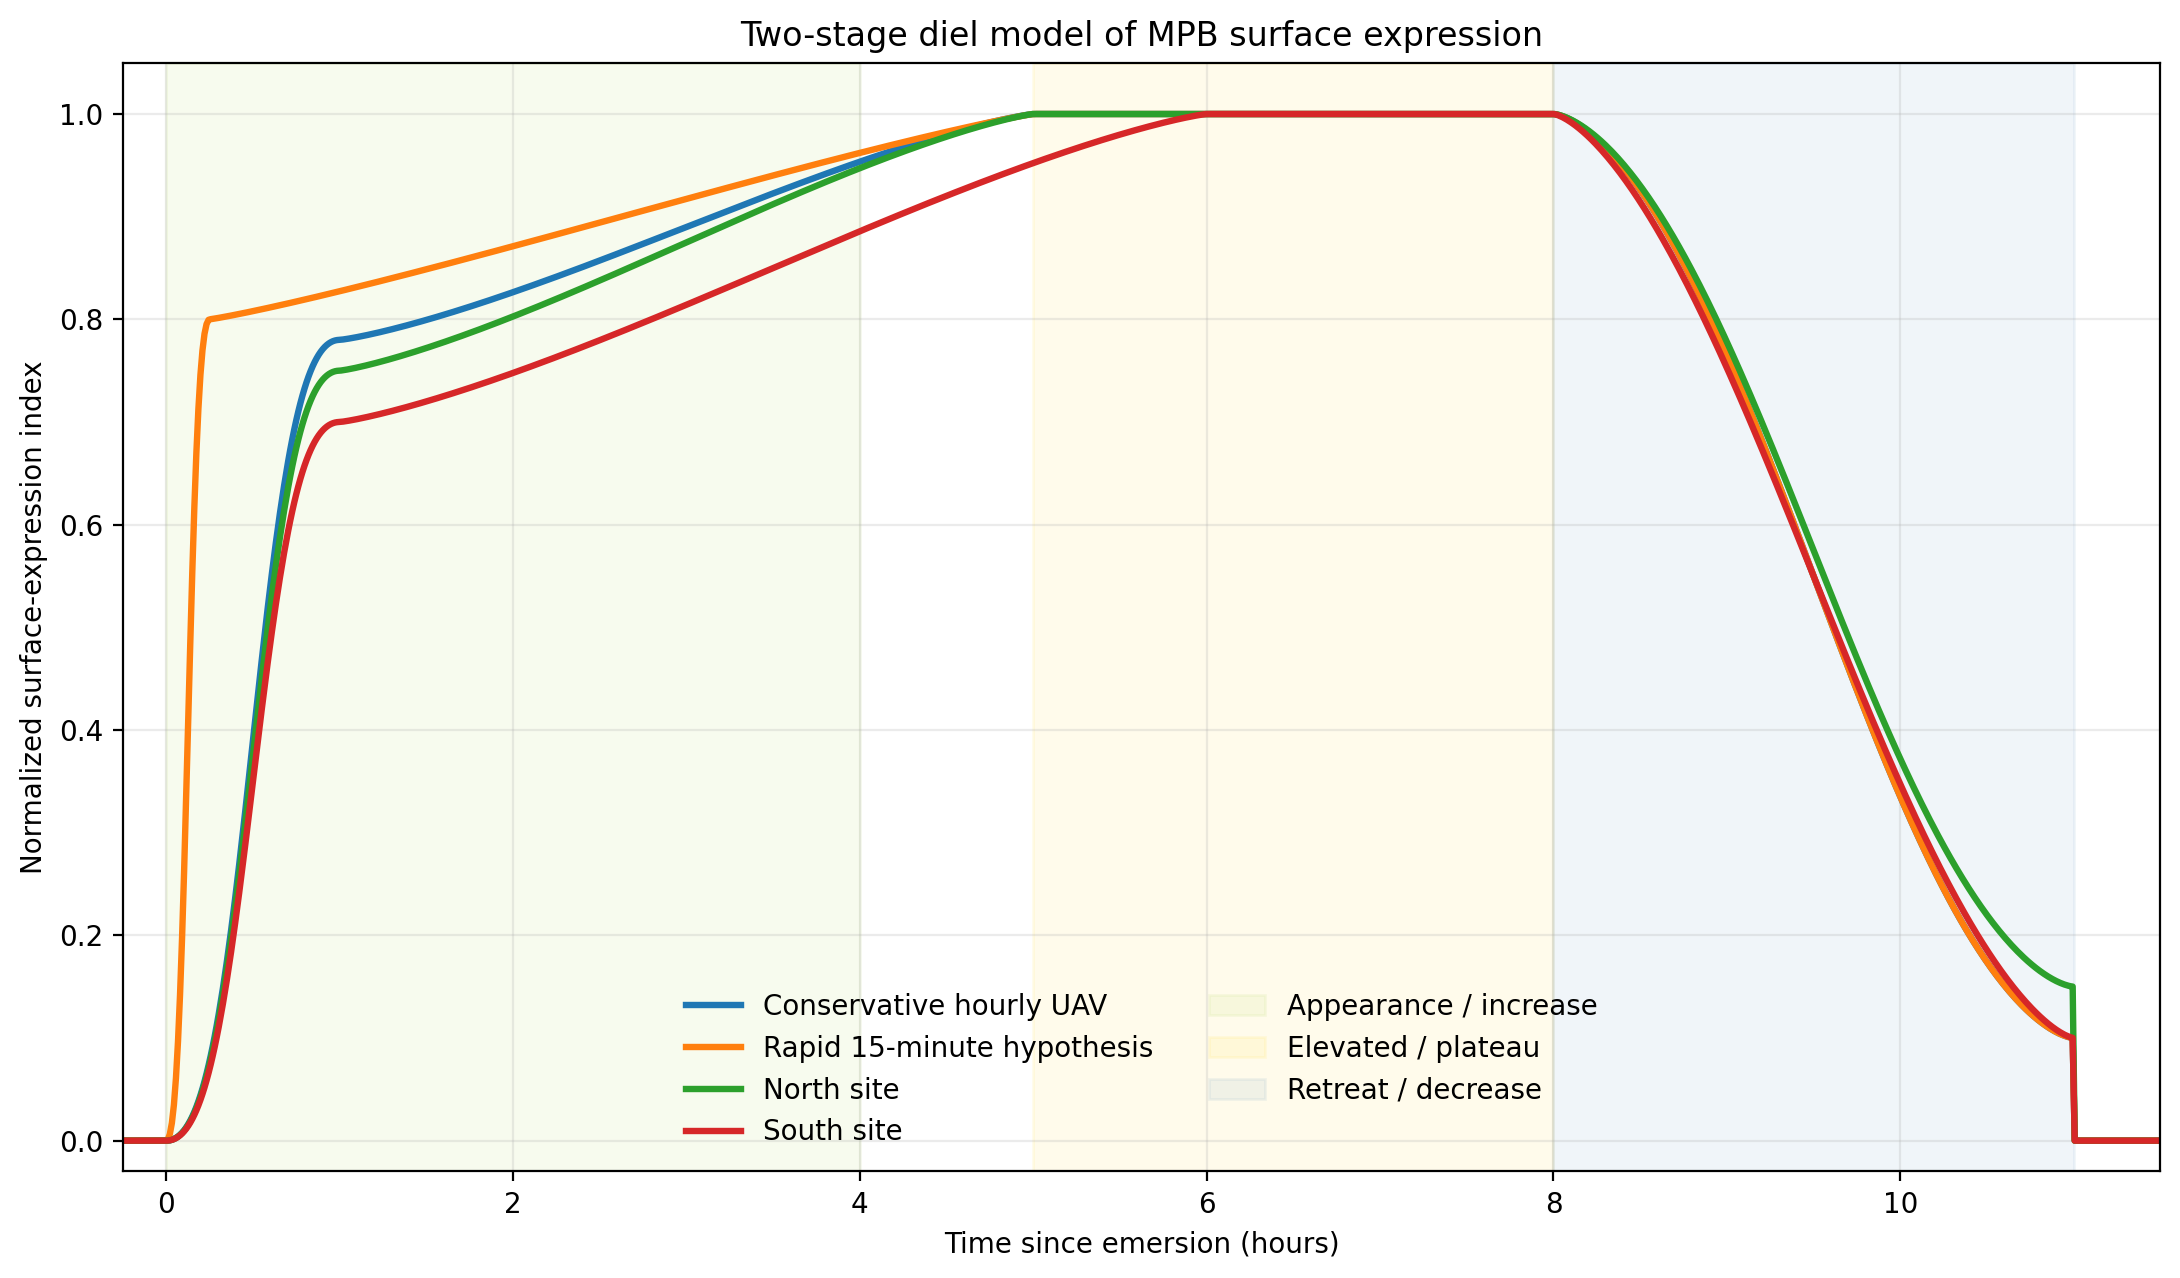

In [138]:
import matplotlib.pyplot as plt
import numpy as np


time = np.linspace(-0.25, 11.5, 1000)

models = {
    "Conservative hourly UAV": UAV_CONSERVATIVE,
    "Rapid 15-minute hypothesis": RAPID_MIGRATION,
    "North site": NORTH_SITE,
    "South site": SOUTH_SITE,
}

fig, ax = plt.subplots(figsize=(11, 6.5))

for label, parameters in models.items():
    expression = diel_biofilm_expression(
        time,
        **parameters,
    )

    ax.plot(
        time,
        expression,
        linewidth=2.3,
        label=label,
    )

# Mark the approximate phases from the notes.
ax.axvspan(
    0,
    4,
    color="yellowgreen",
    alpha=0.08,
    label="Appearance / increase",
)

ax.axvspan(
    5,
    8,
    color="gold",
    alpha=0.08,
    label="Elevated / plateau",
)

ax.axvspan(
    8,
    11,
    color="steelblue",
    alpha=0.08,
    label="Retreat / decrease",
)

ax.set_xlabel("Time since emersion (hours)")
ax.set_ylabel("Normalized surface-expression index")
ax.set_title(
    "Two-stage diel model of MPB surface expression"
)

ax.set_xlim(-0.25, 11.5)
ax.set_ylim(-0.03, 1.05)

ax.grid(alpha=0.25)
ax.legend(
    frameon=False,
    ncol=2,
)

fig.tight_layout()
plt.show()

In [139]:
# Sample N_POINTS times the migration model among available_models keys
migration_models = np.random.default_rng(seed).choice(list(available_models.keys()), size=N_POINTS)

# Apply models with corresponding random hours
fractions = np.array([diel_biofilm_expression(time, **available_models[model]) for model, time in zip(migration_models, emergence_times_hours)])

MIN_MAX_VAL = 0.7
# Random betweem MIN_MAX_VAL and 1, with more towards 1
max_val = MIN_MAX_VAL + (1.0 - MIN_MAX_VAL) * np.random.default_rng(seed).beta(
    a=3.0,
    b=1.5,
    size=N_POINTS,
)

fractions *= max_val

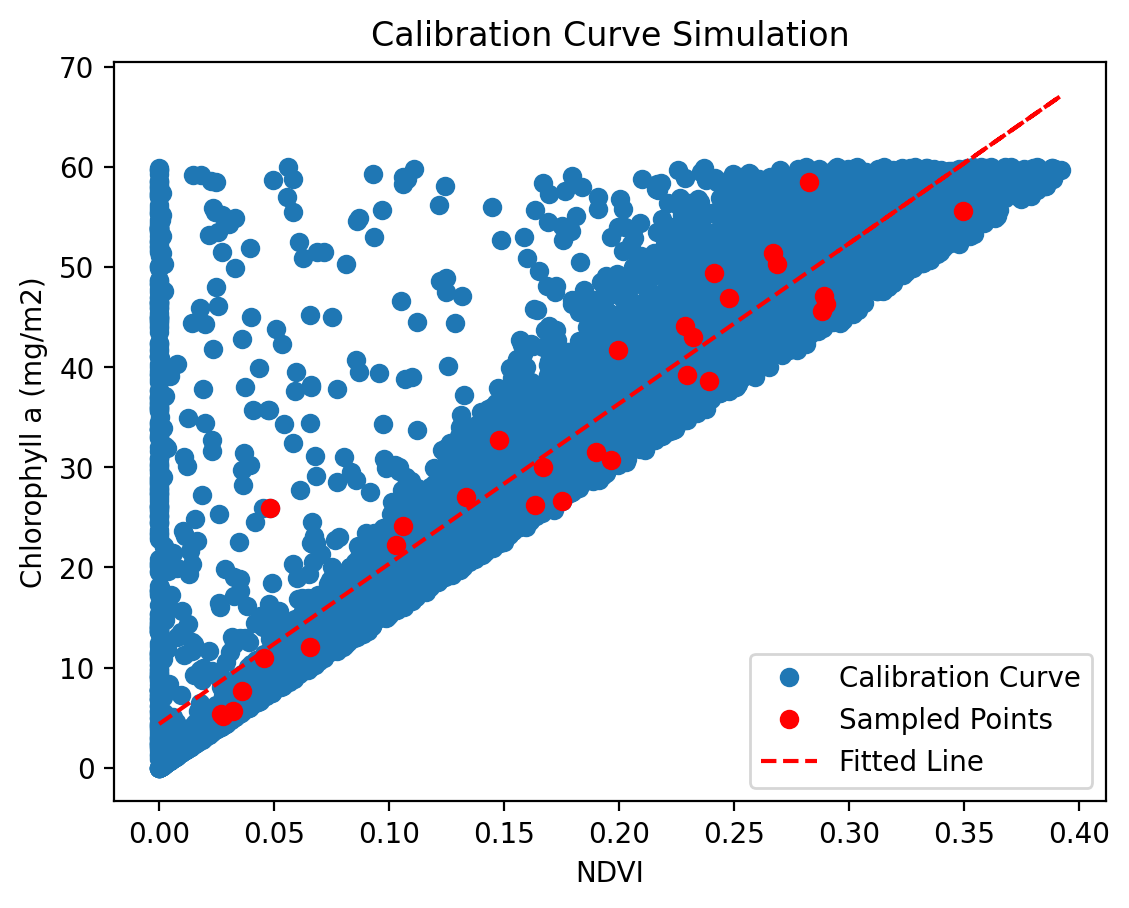

In [140]:
# Plot current curve

ndvi_values_weighted = ndvi_values * fractions

# Select N_SAMPLES
sample_indices = np.random.default_rng(seed).choice(N_POINTS, size=N_SAMPLES, replace=False)

# Fit samples
fit_coeffs = np.polyfit(ndvi_values_weighted[sample_indices], chla_values[sample_indices], deg=1)
fit_line = np.poly1d(fit_coeffs)

plt.plot(ndvi_values_weighted, chla_values, 'o', label="Calibration Curve")
plt.plot(ndvi_values_weighted[sample_indices], chla_values[sample_indices], 'or', label="Sampled Points")
plt.plot(ndvi_values_weighted, fit_line(ndvi_values_weighted), 'r--', label="Fitted Line")
plt.xlabel("NDVI")
plt.ylabel("Chlorophyll a (mg/m2)")
plt.title("Calibration Curve Simulation")
plt.legend()
plt.show()

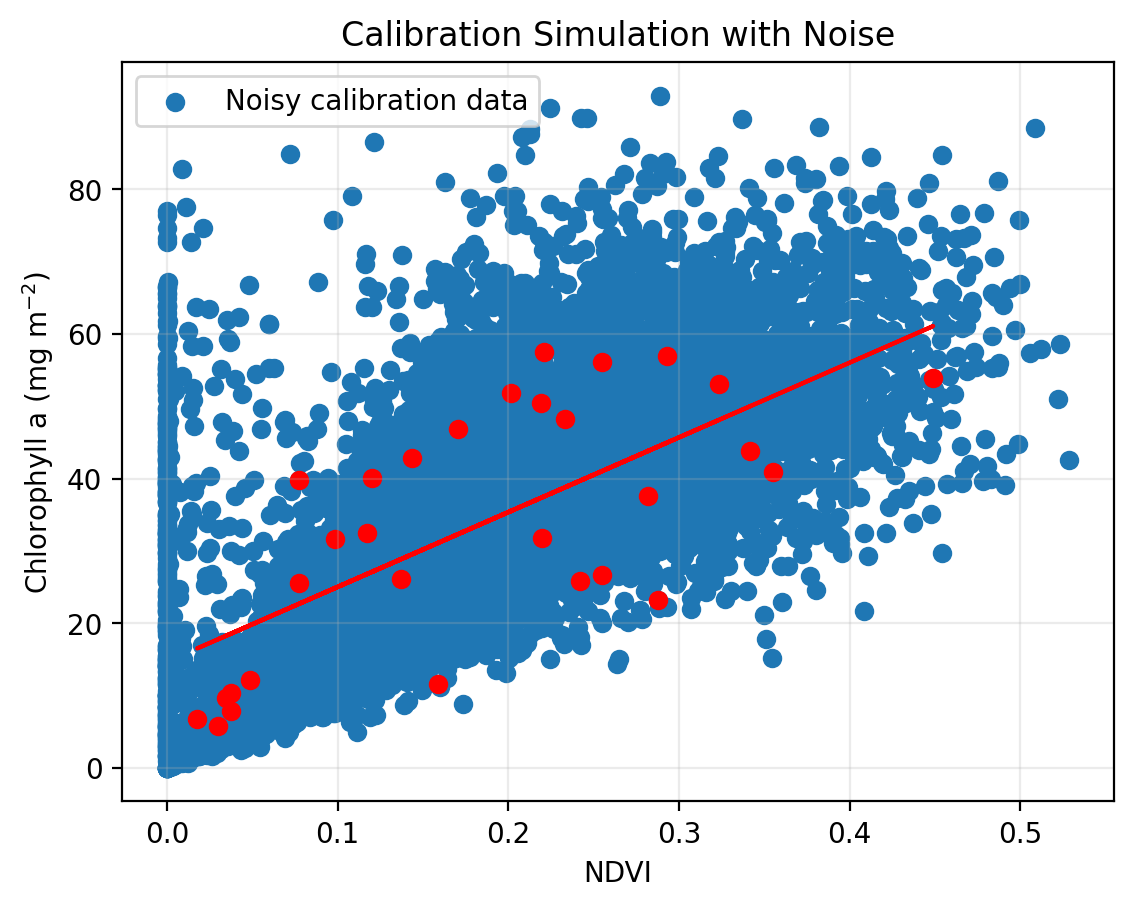

In [141]:
# Add noise


rng = np.random.default_rng(seed)

rel_sd_ndvi = 0.2
rel_sd_chla = 0.2

# Independent relative errors, each with SD = 20%
relative_error_ndvi = rng.normal(
    loc=0.0,
    scale=rel_sd_ndvi,
    size=N_POINTS,
)

relative_error_chla = rng.normal(
    loc=0.0,
    scale=rel_sd_chla,
    size=N_POINTS,
)

ndvi_values_noisy = (
    ndvi_values_weighted
    * (1.0 + relative_error_ndvi)
)

chla_values_noisy = (
    chla_values
    * (1.0 + relative_error_chla)
)

# Keep values above 0
ndvi_values_noisy = np.maximum(ndvi_values_noisy, 0)
chla_values_noisy = np.maximum(chla_values_noisy, 0)

plt.scatter(
    ndvi_values_noisy,
    chla_values_noisy,
    label="Noisy calibration data",
)

plt.xlabel("NDVI")
plt.ylabel(r"Chlorophyll a (mg m$^{-2}$)")
plt.title("Calibration Simulation with Noise")
plt.grid(alpha=0.25)
plt.legend()

# Add samples, fit, and original calibration curve
# Plot samples
plt.scatter(
    ndvi_values_noisy[sample_indices],
    chla_values_noisy[sample_indices],
    color="red",
)

# Fit samples
fit_coeffs = np.polyfit(
    ndvi_values_noisy[sample_indices],
    chla_values_noisy[sample_indices],
    deg=1,
)
fit_line = np.poly1d(fit_coeffs)
plt.plot(
    ndvi_values_noisy[sample_indices],
    fit_line(ndvi_values_noisy[sample_indices]),
    color="red",
    label="Fitted line",
)
